<a href="https://colab.research.google.com/github/mvanamali-27/DIP-rPPG/blob/main/notebooks/04_final_exam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q mediapipe==1.1.0

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
if os.path.isdir("DIP-rPPG"):
    !cd DIP-rPPG && git pull -q
else:
    !git clone -q https://github.com/mvanamali-27/DIP-rPPG.git

In [3]:
import sys, importlib, hashlib
from pathlib import Path
if "DIP-rPPG/src" not in sys.path:
    sys.path.append("DIP-rPPG/src")
import numpy as np
import matplotlib.pyplot as plt
import config, data, roi, extract_all, windows, evaluate, cnn
import signal_proc as sp

for module in (config, data, sp, roi, extract_all, windows, evaluate, cnn):
    importlib.reload(module)

EXAM_DIR = config.DATA_DIR.parent / "RPPG_FINAL_EXAM"
print("exam folder:", EXAM_DIR, "| exists:", EXAM_DIR.exists(), "| training on:", cnn.DEVICE)

exam folder: /content/drive/MyDrive/RPPG_FINAL_EXAM | exists: True | training on: cuda


In [4]:
exam_subs = data.find_subjects(EXAM_DIR)
dev_subs = data.find_subjects()
md5 = lambda path: hashlib.md5(open(path, "rb").read()).hexdigest()
dev_names = {s for s, v, g in dev_subs}
dev_hashes = {md5(g): s for s, v, g in dev_subs}
seen, problems = {}, []
for s, v, g in exam_subs:
    n_video = roi.video_info(v)["n_frames"]
    n_truth = len(data.load_ground_truth(g)[0])
    h = md5(g)
    if abs(n_video - n_truth) > 5:
        problems.append(f"{s}: video has {n_video} frames but the ground truth has {n_truth} samples")
    if h in dev_hashes:
        problems.append(f"{s}: identical ground-truth file to {dev_hashes[h]}, which is in the training data")
    if h in seen:
        problems.append(f"{s}: identical ground-truth file to exam subject {seen[h]}")
    if s in dev_names:
        problems.append(f"{s}: a subject with this name is already in the training data")
    seen[h] = s
print(f"{len(dev_subs)} development subjects, {len(exam_subs)} exam subjects")
print("\n".join(problems) if problems else "all exam subjects pass the checks")

  skip subject_35: 0 mp4, 0 txt
  skip subject_41: 0 mp4, 0 txt
21 development subjects, 17 exam subjects
all exam subjects pass the checks


In [5]:
extract_all.build_all(EXAM_DIR)

  skip subject_35: 0 mp4, 0 txt
  skip subject_41: 0 mp4, 0 txt
[1/17] subject_24: already saved, skipping
[2/17] subject_25: already saved, skipping
[3/17] subject_26: already saved, skipping
[4/17] subject_27: already saved, skipping
[5/17] subject_28: already saved, skipping
[6/17] subject_29: already saved, skipping
[7/17] subject_30: already saved, skipping
[8/17] subject_31: already saved, skipping
[9/17] subject_32: already saved, skipping
[10/17] subject_33: already saved, skipping
[11/17] subject_34: already saved, skipping
[12/17] subject_36: already saved, skipping
[13/17] subject_37: already saved, skipping
[14/17] subject_38: already saved, skipping
[15/17] subject_39: already saved, skipping
[16/17] subject_40: already saved, skipping
[17/17] subject_42: already saved, skipping


In [6]:
exam = windows.build_dataset(path=EXAM_DIR / "dataset.npz", data_dir=EXAM_DIR)

  skip subject_35: 0 mp4, 0 txt
  skip subject_41: 0 mp4, 0 txt
saved 966 windows from 17 subjects -> /content/drive/MyDrive/RPPG_FINAL_EXAM/dataset.npz


In [7]:
!cd DIP-rPPG && git log -1 --format="exam taken with commit %h (%ad): %s" --date=short

exam taken with commit 99f6dbc (2026-10-28): Update windows.py


FINAL EXAM: trained on 21 people, tested on 17 new people

guess the average  MAE 14.20 | RMSE 17.02 | within 5 bpm  17% | per person: avg 14.20, median 12.19, worst 40.97
green + FFT        MAE  2.96 | RMSE  9.98 | within 5 bpm  93% | per person: avg  2.95, median  0.79, worst 18.62
POS + FFT          MAE  0.58 | RMSE  1.34 | within 5 bpm  99% | per person: avg  0.58, median  0.49, worst  1.01
CNN (raw RGB)      MAE  2.95 | RMSE  3.83 | within 5 bpm  84% | per person: avg  2.95, median  2.58, worst  6.33


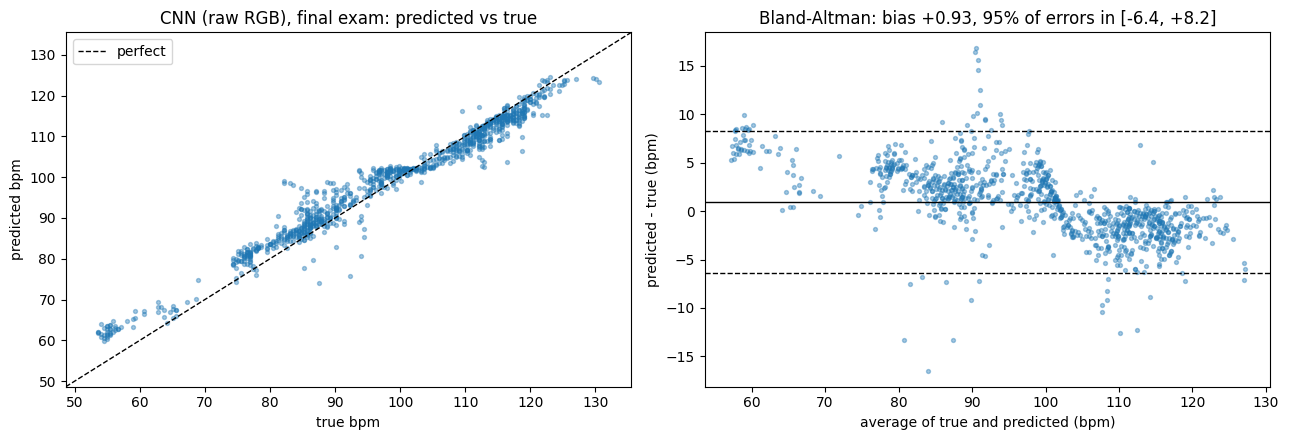

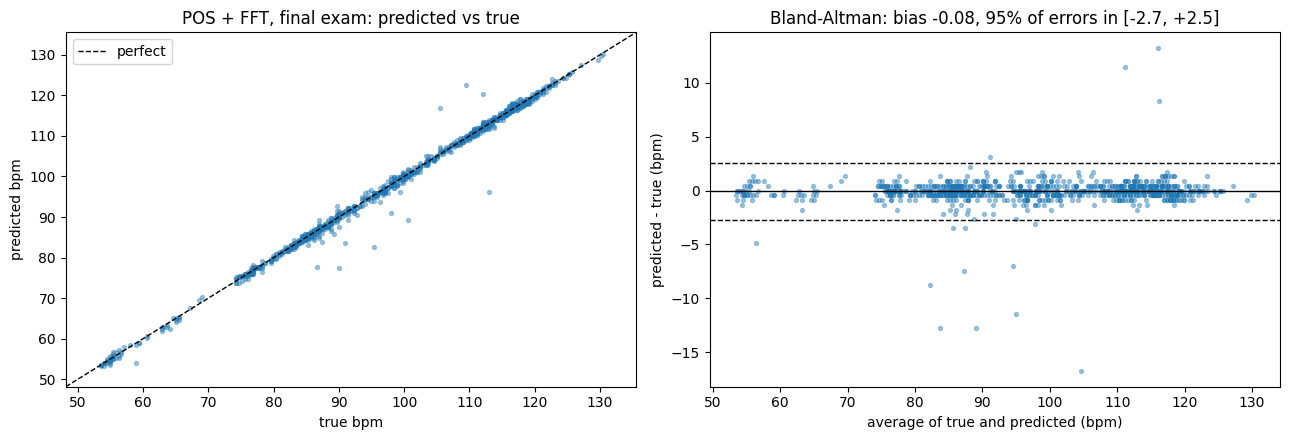

In [4]:
dev = windows.load_dataset() #run once
final = {"guess the average": np.full(len(exam["bpm"]), dev["bpm"].mean()),
         "green + FFT": exam["bpm_green"],
         "POS + FFT": exam["bpm_pos"]}
final["CNN (raw RGB)"] = cnn.CNNRegressor().fit(dev["rgb"], dev["bpm"]).predict(exam["rgb"])

print(f"FINAL EXAM: trained on {len(np.unique(dev['subject']))} people, "
      f"tested on {len(np.unique(exam['subject']))} new people\n")
for name, pred in final.items():
    evaluate.summary(name, exam["bpm"], pred, exam["subject"])
np.savez(EXAM_DIR / "final_predictions.npz", **final)
evaluate.plot_agreement("CNN (raw RGB), final exam", exam["bpm"], final["CNN (raw RGB)"])
evaluate.plot_agreement("POS + FFT, final exam", exam["bpm"], final["POS + FFT"])

In [3]:
import sys, importlib
if "DIP-rPPG/src" not in sys.path:
    sys.path.append("DIP-rPPG/src")
import numpy as np
import matplotlib.pyplot as plt
import config, windows, evaluate, cnn

EXAM_DIR = config.DATA_DIR.parent / "RPPG_FINAL_EXAM"
exam = windows.load_dataset(EXAM_DIR / "dataset.npz")      # built in Step 8, just load it
print(len(np.unique(exam["subject"])), "exam subjects,", len(exam["bpm"]), "windows | training on:", cnn.DEVICE)

17 exam subjects, 966 windows | training on: cpu
